In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [24]:
m = pd.read_csv('machines.csv')
p = pd.read_csv('production_log.csv')

In [25]:
p.head()

,date,machine_id,shift,units,defects,downtime_min
0,2025-01-01,M01,Night,81.0,7,90
1,2025-01-01,M02,Day,132.0,7,67
2,2025-01-01,M03,Day,160.0,11,71
3,2025-01-01,M04,Day,199.0,8,50
4,2025-01-01,M06,Day,79.0,1,37


In [26]:
p.isna().sum()

date             0
machine_id       0
shift            0
units           20
defects          0
downtime_min     0
dtype: int64

In [27]:
p.duplicated().sum()

np.int64(12)

In [28]:
p['shift'].value_counts()

shift
Day      1012
Night    1001
NIGHT      20
day        15
DAY        15
night      10
Name: count, dtype: int64

In [29]:
(p['units'] < 0).sum()

np.int64(8)

In [30]:
p['date'].str.contains('.', regex=False).sum()

np.int64(25)

In [31]:
~p['machine_id'].isin(m['machine_id'])

0       False
1       False
2       False
3       False
4       False
        ...  
2068    False
2069    False
2070    False
2071    False
2072    False
Name: machine_id, Length: 2073, dtype: bool

In [32]:
def clean_log(df):
    df = df.copy()
    df['date'] = pd.to_datetime(p['date'], format='mixed',dayfirst=True)
    df['shift'] = df['shift'].str.strip().str.capitalize()
    df.loc[df['units'] < 0, 'units'] = np.nan
    df = df.drop_duplicates()
    df = df.dropna(subset=['units'])
    return df

c = clean_log(p)

In [33]:
print(c['date'].dtype, c['date'].isna().sum())   # datetime64[...]  0
print(c['shift'].nunique())                      # 2
print(c.duplicated().sum())                      # 0
print((c['units'] < 0).sum())                    # 0
print(c['date'].min(), c['date'].max())          # 2025-01-01  2025-12-31

datetime64[us] 0
2
0
0
2025-01-01 00:00:00 2025-12-31 00:00:00


In [34]:
unknown = ~c['machine_id'].isin(m['machine_id'])
print(unknown.sum(), c[unknown]['machine_id'].unique())   # 15  ['M07']

15 <ArrowStringArray>
['M07']
Length: 1, dtype: str


In [35]:
df = pd.merge(c, m, on='machine_id', how='inner')
df['machine_age'] = 2025 - df['install_year']

In [36]:
df.head(10)

,date,machine_id,shift,units,defects,downtime_min,type,plant,install_year,machine_age
0,2025-01-01,M01,Night,81.0,7,90,CNC,North,2015,10
1,2025-01-01,M02,Day,132.0,7,67,CNC,North,2019,6
2,2025-01-01,M03,Day,160.0,11,71,Press,North,2012,13
3,2025-01-01,M04,Day,199.0,8,50,Press,South,2020,5
4,2025-01-01,M06,Day,79.0,1,37,Welder,South,2022,3
5,2025-02-01,M01,Night,96.0,5,80,CNC,North,2015,10
6,2025-02-01,M02,Night,93.0,6,66,CNC,North,2019,6
7,2025-02-01,M03,Day,171.0,12,95,Press,North,2012,13
8,2025-02-01,M04,Day,160.0,8,26,Press,South,2020,5
9,2025-02-01,M05,Day,86.0,5,103,Welder,South,2017,8


In [37]:
print(df['type'].isna().sum(),
      df['plant'].isna().sum(),
      df['install_year'].isna().sum())
print(len(df), len(c) - 15)                                                                # equal

0 0 0
2018 2018


In [38]:
df['month'] = df['date'].dt.month
monthly = df.groupby('month')['units'].sum()

In [44]:
daily_avg = df.groupby('month')['units'].mean()

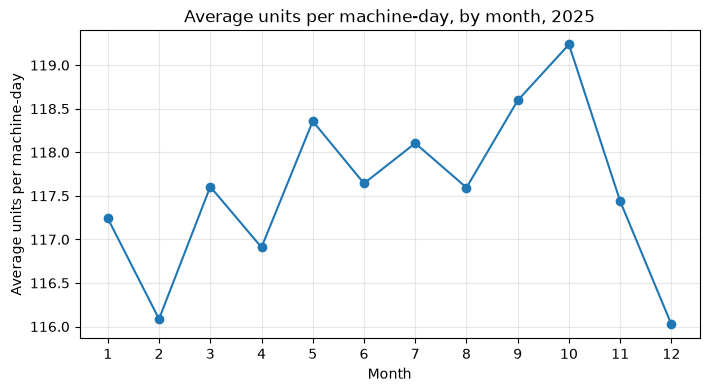

In [46]:
plt.figure(figsize=(8,4))
plt.plot(daily_avg.index, daily_avg.values, marker='o')
plt.title('Average units per machine-day, by month, 2025')
plt.xlabel('Month')
plt.ylabel('Average units per machine-day')
plt.grid(True, alpha=0.3)
plt.xticks(range(1,13))
plt.show()

In [47]:
df['defect_rate'] = df['defects'] / df['units']

In [49]:
by_shift = df.groupby('shift')['defect_rate'].mean()
by_type = df.groupby('type')['defect_rate'].mean()

print(by_type)
print(by_shift)

type
CNC       0.056860
Press     0.060335
Welder    0.047807
Name: defect_rate, dtype: float64
shift
Day      0.050123
Night    0.059842
Name: defect_rate, dtype: float64


In [53]:
g = df.groupby('type')[['defects', 'units']].sum()
g['rate'] = g['defects'] / g['units']
print(g)

        defects     units      rate
type                               
CNC        4010   70838.0  0.056608
Press      6942  116768.0  0.059451
Welder     2352   49684.0  0.047339


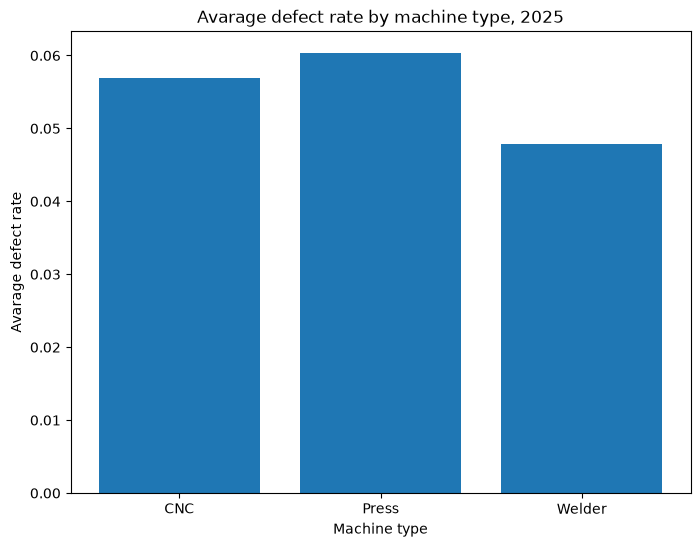

In [56]:
plt.figure(figsize=(8,6))
plt.bar(by_type.index, by_type.values)
plt.title('Avarage defect rate by machine type, 2025')
plt.xlabel('Machine type')
plt.ylabel('Avarage defect rate')
plt.show()

In [59]:
print(by_shift)

g = df.groupby('shift')[['defects', 'units']].sum()
g['rate'] = g['defects'] / g['units']
print(g)


shift
Day      0.050123
Night    0.059842
Name: defect_rate, dtype: float64
       defects     units      rate
shift                             
Day       6453  126215.0  0.051127
Night     6851  111075.0  0.061679


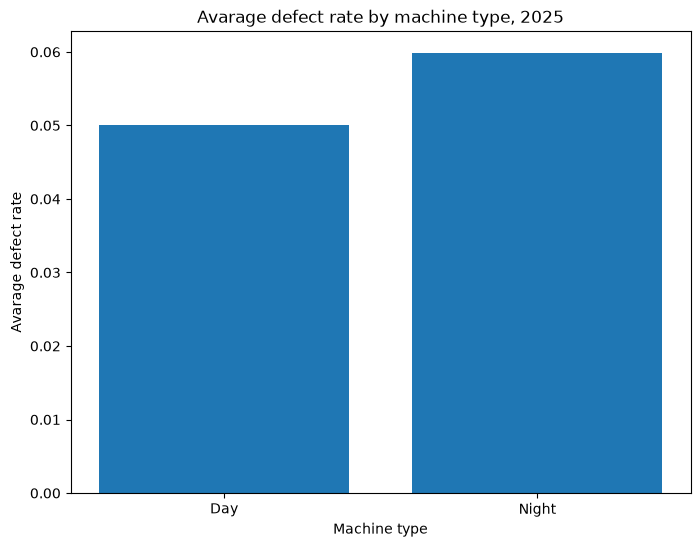

In [60]:
plt.figure(figsize=(8,6))
plt.bar(by_shift.index, by_shift.values)
plt.title('Avarage defect rate by machine type, 2025')
plt.xlabel('Machine type')
plt.ylabel('Avarage defect rate')
plt.show()

In [61]:
print(df.groupby(['type', 'shift'])['defect_rate'].mean())

type    shift
CNC     Day      0.052611
        Night    0.061452
Press   Day      0.054367
        Night    0.066691
Welder  Day      0.042921
        Night    0.052215
Name: defect_rate, dtype: float64


In [ ]:
result = df.groupby('machine_id').agg(
    downtime=('downtime_min', 'mean'),
    age=('machine_age', 'first')
)

In [67]:
result.head(6)

,downtime,age
machine_id,,
M01,78.620588,10
M02,59.675758,6
M03,95.523810,13
M04,56.525680,5
M05,68.289086,8
M06,47.298246,3


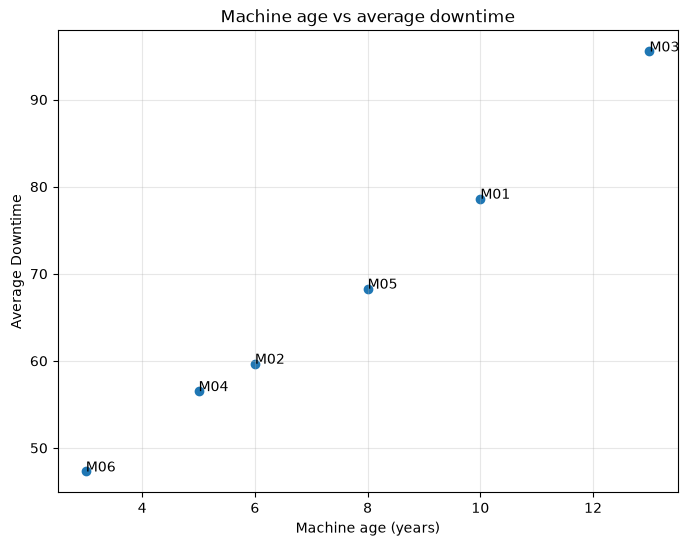

In [73]:
plt.figure(figsize=(8, 6))
plt.scatter(result['age'], result['downtime'])
for mid, row in result.iterrows():
    plt.annotate(mid, (row['age'], row['downtime']))
plt.title('Machine age vs average downtime')
plt.xlabel('Machine age (years)')
plt.ylabel('Average Downtime')
plt.grid(True, alpha=0.3)
plt.show()

In [74]:
print(result['age'].corr(result['downtime']))

0.996928343091933


In [76]:
slope, intercept = np.polyfit(result['age'], result['downtime'], 1)
print(slope)

4.769572896480679


In [77]:
df['weekday'] = df['date'].dt.day_name()
by_weekday = df.groupby('weekday')['units'].mean()

In [78]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
by_weekday = by_weekday.reindex(order)

In [81]:
print(by_weekday.idxmax(), by_weekday.max())
print(by_weekday.idxmin(), by_weekday.min())

Tuesday 120.25352112676056
Friday 116.68181818181819


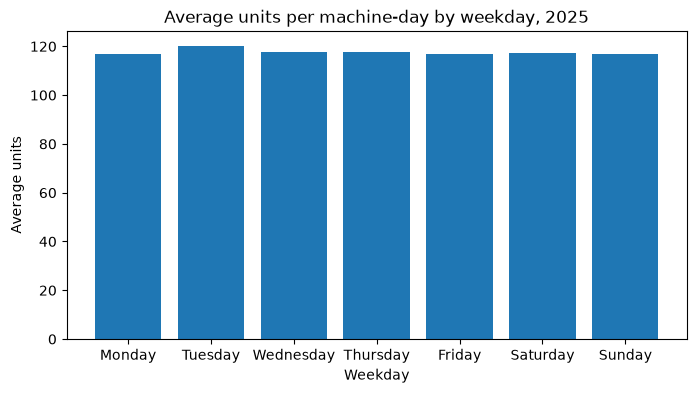

In [82]:
plt.figure(figsize=(8, 4))
plt.bar(by_weekday.index, by_weekday.values)
plt.title('Average units per machine-day by weekday, 2025')
plt.xlabel('Weekday')
plt.ylabel('Average units')
plt.show()

In [83]:
print(by_weekday.idxmax(), by_weekday.max())
print(by_weekday.idxmin(), by_weekday.min())
print(by_weekday.max() - by_weekday.min())

Tuesday 120.25352112676056
Friday 116.68181818181819
3.5717029449423734
